# Klasifikasi Kategori Biaya Kuliah Mahasiswa dengan CatBoost Baseline

Proyek portofolio Data Mining yang membangun model **klasifikasi multikelas** untuk memprediksi `kategori_biaya_kuliah` menggunakan **CatBoost + Class Weighting**.

> **Catatan dataset:** file yang disertakan adalah dataset latihan sintetis untuk pembelajaran, bukan dataset resmi GEMASTIK dan bukan data mahasiswa nyata.

## Tujuan proyek

- Membangun alur machine learning dari audit data sampai evaluasi model.
- Menangani target tidak seimbang dengan `auto_class_weights="Balanced"`.
- Mengukur baseline menggunakan Stratified 5-Fold Cross-Validation.
- Mengevaluasi performa pada holdout test set dengan metrik multikelas dan confusion matrix.
- Menyimpan model dan hasil evaluasi agar eksperimen dapat direproduksi.

## Alur kerja

1. Memuat dan mengaudit dataset.
2. Membersihkan target, merapikan tipe data, serta menyiapkan fitur kategorikal dan numerik.
3. Memisahkan fitur dan target serta mengecualikan kolom ID.
4. Membagi data training/testing secara stratified dengan proporsi 80:20.
5. Menjalankan Stratified 5-Fold Cross-Validation pada data training.
6. Melatih satu model CatBoost baseline pada seluruh data training.
7. Mengukur Accuracy, Balanced Accuracy, Macro F1, Weighted F1, recall per kelas, dan confusion matrix.
8. Melihat feature importance dan menyimpan model serta laporan.

**Tidak ada hyperparameter tuning dalam proyek ini.** Parameter baseline dipertahankan tetap agar kode tetap sederhana, cepat dipahami, dan mudah digunakan sebagai baseline pembanding.

## 0. Persiapan environment

Pastikan environment Python telah menginstal library pada file `requirements.txt` dari folder utama repo.

Jika perlu menjalankan instalasi dari Jupyter, buka cell di bawah ini dan hapus tanda komentar.

In [1]:
# Jalankan jika library belum terpasang.
# %pip install -r ../requirements.txt

## 1. Import library dan konfigurasi eksperimen

Nilai `RANDOM_STATE` ditetapkan agar split dan pembagian fold dapat direproduksi. Stratified split mempertahankan proporsi kelas secara kurang lebih sama pada training dan test.

In [2]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import catboost
from catboost import CatBoostClassifier
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

DATA_FILENAME = "dataset_latihan_gemastik_mahasiswa.csv"
ID_COL = "id_mahasiswa"
TARGET_COL = "kategori_biaya_kuliah"
RANDOM_STATE = 2026
TEST_SIZE = 0.20
N_SPLITS = 5

# Temukan root proyek agar notebook bekerja ketika dijalankan dari folder utama
# repo ataupun dari subfolder notebooks/.
possible_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (
        root for root in possible_roots
        if (root / "data" / DATA_FILENAME).exists() or (root / DATA_FILENAME).exists()
    ),
    Path.cwd().resolve(),
)

candidate_paths = [
    PROJECT_ROOT / "data" / DATA_FILENAME,
    PROJECT_ROOT / DATA_FILENAME,
    Path.cwd() / DATA_FILENAME,
    Path.cwd() / "data" / DATA_FILENAME,
]
DATA_PATH = next((path for path in candidate_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Dataset {DATA_FILENAME} tidak ditemukan. Letakkan file di folder data/ repo."
    )

OUTPUT_DIR = PROJECT_ROOT / "artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi baseline tetap, tanpa hyperparameter tuning.
BASELINE_PARAMS = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5,
    "loss_function": "MultiClass",
    "eval_metric": "MultiClass",
    "auto_class_weights": "Balanced",
    "random_seed": RANDOM_STATE,
    "verbose": 0,
    "allow_writing_files": False,
    "thread_count": 1,
}

print(f"Python environment: CatBoost {catboost.__version__} | scikit-learn {sklearn.__version__}")
print(f"Dataset: {DATA_PATH}")
print(f"Jumlah fold CV: {N_SPLITS}")
print("Strategi imbalance: Class Weighting (auto_class_weights='Balanced')")

Python environment: CatBoost 1.2.10 | scikit-learn 1.4.2
Dataset: D:\Documents\Gemastik\Tabular\Latihan Kategoti mahahsiswa\gemastik-catboost-baseline-portfolio\data\dataset_latihan_gemastik_mahasiswa.csv
Jumlah fold CV: 5
Strategi imbalance: Class Weighting (auto_class_weights='Balanced')


## 2. Memuat dan mengaudit dataset

Pada tahap audit, periksa ukuran data, nama kolom, nilai kosong, baris duplikat, dan distribusi target. Distribusi target penting karena model memprediksi kelas dengan frekuensi yang tidak sama.

In [3]:
df = pd.read_csv(DATA_PATH)

if TARGET_COL not in df.columns:
    raise KeyError(
        f"Kolom target '{TARGET_COL}' tidak ditemukan. Kolom tersedia: {df.columns.tolist()}"
    )

print(f"Ukuran dataset awal: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Jumlah kolom fitur selain ID dan target: {len(df.columns) - 2}")
print(f"Jumlah baris duplikat penuh: {int(df.duplicated().sum())}")

print("\nSampel data:")
display(df.head())

missing_summary = df.isna().sum().sort_values(ascending=False)
print("\nKolom yang memiliki missing value:")
display(missing_summary[missing_summary > 0].to_frame("jumlah_missing"))

class_counts = df[TARGET_COL].value_counts(dropna=False).sort_index()
class_distribution = pd.DataFrame({
    "jumlah": class_counts,
    "persentase": (class_counts / len(df) * 100).round(2),
})
print("\nDistribusi target:")
display(class_distribution)

ax = class_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribusi Kategori Biaya Kuliah")
ax.set_xlabel("Kategori")
ax.set_ylabel("Jumlah data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Ukuran dataset awal: 1,200 baris x 20 kolom
Jumlah kolom fitur selain ID dan target: 18
Jumlah baris duplikat penuh: 0

Sampel data:


,id_mahasiswa,usia,program_studi,jenis_atap,jenis_lantai,jenis_dinding,status_rumah,sumber_air,sumber_listrik,pekerjaan_ayah,pekerjaan_ibu,pendidikan_orangtua,status_beasiswa,jalur_masuk,penghasilan_ayah,penghasilan_ibu,jumlah_tanggungan,pengeluaran_bulanan,aset_keluarga,kategori_biaya_kuliah
0,MHS0001,20,Sistem Informasi,Beton,Semen,Tembok,Milik sendiri,PDAM,PLN 900 VA,Tidak bekerja,Ibu rumah tangga,Pascasarjana,Tidak,Mandiri,8700000.0,6400000.0,3,10791790.0,3.0,5
1,MHS0002,18,Manajemen,Seng,Tanah,Tembok,Milik sendiri,PDAM,PLN 1300 VA,Wiraswasta,Karyawan swasta,SMA/SMK,Tidak,SNBP,9750000.0,1050000.0,1,6229843.0,3.0,4
2,MHS0003,20,Ilmu Komunikasi,Asbes,Semen,Tembok,Kontrak/sewa,Sumur terlindungi,PLN 900 VA,Wiraswasta,Ibu rumah tangga,Pascasarjana,Tidak,SNBT,1950000.0,2550000.0,4,4584496.0,1.0,3
3,MHS0004,21,Sistem Informasi,Seng,Tanah,Tembok,Milik sendiri,PDAM,PLN 900 VA,Wiraswasta,Ibu rumah tangga,SMA/SMK,Ya,Mandiri,3300000.0,450000.0,6,2932881.0,3.0,2
4,MHS0005,20,Informatika,Beton,Tanah,Tembok,Menumpang keluarga,PDAM,PLN 1300 VA,Karyawan swasta,Karyawan swasta,Sarjana,Tidak,SNBT,NaN,4050000.0,2,5513810.0,4.0,5



Kolom yang memiliki missing value:


,jumlah_missing
penghasilan_ibu,54
penghasilan_ayah,42
aset_keluarga,36
pengeluaran_bulanan,36
pekerjaan_ibu,30
pendidikan_orangtua,30
status_rumah,24
sumber_air,24



Distribusi target:


,jumlah,persentase
kategori_biaya_kuliah,,
1,60,5.0
2,108,9.0
3,204,17.0
4,336,28.0
5,492,41.0


<Figure size 700x400 with 1 Axes>

## 3. Pembersihan data dan persiapan fitur

- Baris duplikat penuh dihapus.
- Target yang kosong atau tidak valid dikeluarkan, lalu target dikonversi menjadi integer.
- Kolom ID tidak digunakan sebagai fitur prediksi.
- Fitur kategorikal dipertahankan dalam format string agar CatBoost dapat memprosesnya secara native.
- Nilai kosong pada fitur kategorikal diberi label `__MISSING__`. Nilai numerik yang tidak dapat dikonversi menjadi angka menjadi `NaN`; CatBoost mendukung missing value pada fitur numerik.
- Tidak dilakukan one-hot encoding.

In [4]:
df_clean = df.copy()

n_duplicates_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

df_clean[TARGET_COL] = pd.to_numeric(df_clean[TARGET_COL], errors="coerce")
n_invalid_target_removed = int(df_clean[TARGET_COL].isna().sum())
df_clean = df_clean.dropna(subset=[TARGET_COL]).copy()

if not np.all(np.isclose(df_clean[TARGET_COL] % 1, 0)):
    raise ValueError("Target berisi nilai non-integer. Periksa label target terlebih dahulu.")

df_clean[TARGET_COL] = df_clean[TARGET_COL].astype(int)
df_clean = df_clean.reset_index(drop=True)

y = df_clean[TARGET_COL].copy()
X = df_clean.drop(columns=[TARGET_COL, ID_COL], errors="ignore").copy()

# Tentukan kolom kategorikal berdasarkan tipe data sebelum konversi.
CAT_COLS = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
NUM_COLS = [col for col in X.columns if col not in CAT_COLS]

missing_tokens = {"": pd.NA, "nan": pd.NA, "NaN": pd.NA, "None": pd.NA, "<NA>": pd.NA}
for col in CAT_COLS:
    values = X[col].astype("string").str.strip()
    values = values.replace(missing_tokens)
    X[col] = values.fillna("__MISSING__").astype(str)

for col in NUM_COLS:
    X[col] = pd.to_numeric(X[col], errors="coerce")

FEATURES = X.columns.tolist()
LABELS = sorted(y.unique().tolist())

print("Duplikat yang dihapus:", n_duplicates_removed)
print("Baris dengan target kosong/tidak valid yang dihapus:", n_invalid_target_removed)
print("Jumlah baris setelah pembersihan:", len(df_clean))
print("Jumlah fitur yang digunakan:", len(FEATURES))
print("Fitur kategorikal:", CAT_COLS)
print("Fitur numerik:", NUM_COLS)
print("Label target:", LABELS)

assert ID_COL not in FEATURES, "Kolom ID tidak boleh menjadi fitur prediksi."
assert TARGET_COL not in FEATURES, "Target tidak boleh menjadi fitur prediksi."
assert len(FEATURES) == 18, f"Ekspektasi 18 fitur, ditemukan {len(FEATURES)}. Periksa struktur dataset."

display(y.value_counts().sort_index().to_frame("jumlah_setelah_pembersihan"))

Duplikat yang dihapus: 0
Baris dengan target kosong/tidak valid yang dihapus: 0
Jumlah baris setelah pembersihan: 1200
Jumlah fitur yang digunakan: 18
Fitur kategorikal: ['program_studi', 'jenis_atap', 'jenis_lantai', 'jenis_dinding', 'status_rumah', 'sumber_air', 'sumber_listrik', 'pekerjaan_ayah', 'pekerjaan_ibu', 'pendidikan_orangtua', 'status_beasiswa', 'jalur_masuk']
Fitur numerik: ['usia', 'penghasilan_ayah', 'penghasilan_ibu', 'jumlah_tanggungan', 'pengeluaran_bulanan', 'aset_keluarga']
Label target: [1, 2, 3, 4, 5]


,jumlah_setelah_pembersihan
kategori_biaya_kuliah,
1,60
2,108
3,204
4,336
5,492


## 4. Train-test split

Data dibagi menjadi 80% training dan 20% testing menggunakan `stratify=y`. Data test disimpan untuk evaluasi akhir dan tidak digunakan saat cross-validation.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_distribution = pd.DataFrame({
    "seluruh_data_%": y.value_counts(normalize=True).sort_index() * 100,
    "training_%": y_train.value_counts(normalize=True).sort_index() * 100,
    "testing_%": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)

print(f"Training: {X_train.shape[0]} baris")
print(f"Testing : {X_test.shape[0]} baris")
print(f"Jumlah fitur: {X_train.shape[1]}")
display(split_distribution)

assert list(X_train.columns) == FEATURES
assert list(X_test.columns) == FEATURES
assert y_train.index.equals(X_train.index)
assert y_test.index.equals(X_test.index)

Training: 960 baris
Testing : 240 baris
Jumlah fitur: 18


,seluruh_data_%,training_%,testing_%
kategori_biaya_kuliah,,,
1,5.0,5.00,5.00
2,9.0,8.96,9.17
3,17.0,16.98,17.08
4,28.0,28.02,27.92
5,41.0,41.04,40.83


## 5. Konfigurasi model baseline

Model yang digunakan hanya satu: **CatBoostClassifier multiclass dengan Class Weighting**. Parameter tidak dicari atau dioptimalkan. `auto_class_weights="Balanced"` meminta CatBoost menyesuaikan bobot berdasarkan distribusi kelas di data yang digunakan untuk fit.

In [6]:
print("Parameter CatBoost baseline:")
display(pd.DataFrame(
    [{"parameter": key, "nilai": value} for key, value in BASELINE_PARAMS.items()]
))

Parameter CatBoost baseline:


,parameter,nilai
0,iterations,500
1,depth,6
2,learning_rate,0.05
3,l2_leaf_reg,5
4,loss_function,MultiClass
5,eval_metric,MultiClass
6,auto_class_weights,Balanced
7,random_seed,2026
8,verbose,0
9,allow_writing_files,False


## 6. Stratified 5-Fold Cross-Validation

Cross-validation dijalankan hanya pada data training. Setiap fold membentuk model baru dan memasukkan nama kolom kategorikal melalui `fit()`. Loop manual dipakai agar tidak mengalami masalah cloning estimator dari kombinasi CatBoost dan scikit-learn.

Progress bar bertambah setiap satu fold selesai. Metrik utama untuk membaca performa lintas kelas adalah **Macro F1**; Balanced Accuracy dan metrik lainnya menjadi pendukung.

In [7]:
def calculate_metrics(y_true, y_pred, labels):
    """Hitung metrik utama dan metrik recall/F1 untuk setiap kelas."""
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    per_class_recall = recall_score(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    per_class_f1 = f1_score(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    for idx, label in enumerate(labels):
        result[f"recall_{label}"] = float(per_class_recall[idx])
        result[f"f1_{label}"] = float(per_class_f1[idx])
    return result

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_rows = []
cv_start = time.perf_counter()

with tqdm(total=N_SPLITS, desc="Baseline CatBoost CV", unit="fold", dynamic_ncols=True) as progress:
    for fold_number, (fit_indices, valid_indices) in enumerate(cv.split(X_train, y_train), start=1):
        X_fold_train = X_train.iloc[fit_indices].copy()
        y_fold_train = y_train.iloc[fit_indices].copy()
        X_fold_valid = X_train.iloc[valid_indices].copy()
        y_fold_valid = y_train.iloc[valid_indices].copy()

        fold_model = CatBoostClassifier(**BASELINE_PARAMS)
        fit_start = time.perf_counter()
        fold_model.fit(X_fold_train, y_fold_train, cat_features=CAT_COLS)
        fit_seconds = time.perf_counter() - fit_start

        y_fold_pred = np.asarray(fold_model.predict(X_fold_valid)).ravel()
        fold_metrics = calculate_metrics(y_fold_valid, y_fold_pred, LABELS)
        cv_rows.append({
            "fold": fold_number,
            "fit_seconds": fit_seconds,
            **fold_metrics,
        })

        progress.update(1)
        progress.set_postfix(
            fold=f"{fold_number}/{N_SPLITS}",
            macro_f1=f"{fold_metrics['macro_f1']:.4f}",
        )

cv_elapsed_seconds = time.perf_counter() - cv_start
cv_results = pd.DataFrame(cv_rows)

print(f"Total waktu cross-validation: {cv_elapsed_seconds:.1f} detik")
print("Skor per fold:")
display(cv_results.round(4))

Baseline CatBoost CV:   0%|          | 0/5 [00:00<?, ?fold/s]

Total waktu cross-validation: 515.9 detik
Skor per fold:


,fold,fit_seconds,accuracy,balanced_accuracy,macro_f1,weighted_f1,recall_1,f1_1,recall_2,f1_2,recall_3,f1_3,recall_4,f1_4,recall_5,f1_5
0,1,110.4855,0.6927,0.7027,0.6781,0.6916,0.8889,0.7619,0.6471,0.6111,0.6061,0.6349,0.5741,0.5849,0.7975,0.7975
1,2,101.1980,0.6198,0.5941,0.5863,0.6179,0.6667,0.6316,0.3889,0.4242,0.6970,0.6389,0.5000,0.5094,0.7179,0.7273
2,3,104.7170,0.6927,0.6263,0.6273,0.6946,0.5000,0.5263,0.5294,0.5000,0.6562,0.6667,0.6481,0.6306,0.7975,0.8129
3,4,99.9522,0.6198,0.5440,0.5550,0.6130,0.5000,0.5556,0.3529,0.3871,0.5938,0.5758,0.4630,0.4854,0.8101,0.7711
4,5,99.4059,0.7083,0.6379,0.6276,0.7126,0.4000,0.4444,0.6471,0.5500,0.6970,0.6479,0.6226,0.6346,0.8228,0.8609


## 7. Ringkasan cross-validation

Nilai `mean` adalah performa rata-rata dari lima fold, sementara `std` menunjukkan variasi antarfold. Standar deviasi yang lebih kecil dapat menunjukkan hasil yang lebih konsisten pada pembagian fold ini.

In [8]:
CV_METRICS = [
    "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
    "recall_1", "recall_2", "recall_3", "f1_1", "f1_2", "f1_3",
]
cv_summary = cv_results[CV_METRICS].agg(["mean", "std"]).T.reset_index()
cv_summary.columns = ["metrik", "mean", "std"]
display(cv_summary.round(4))

print(f"Macro F1 CV: {cv_results['macro_f1'].mean():.4f} ± {cv_results['macro_f1'].std(ddof=1):.4f}")
print(f"Balanced Accuracy CV: {cv_results['balanced_accuracy'].mean():.4f} ± {cv_results['balanced_accuracy'].std(ddof=1):.4f}")

,metrik,mean,std
0,accuracy,0.6667,0.0433
1,balanced_accuracy,0.6210,0.0584
2,macro_f1,0.6148,0.0467
3,weighted_f1,0.6659,0.0468
4,recall_1,0.5911,0.1920
5,recall_2,0.5131,0.1390
6,recall_3,0.6500,0.0489
7,f1_1,0.5840,0.1199
8,f1_2,0.4945,0.0911
9,f1_3,0.6328,0.0342


Macro F1 CV: 0.6148 ± 0.0467
Balanced Accuracy CV: 0.6210 ± 0.0584


## 8. Melatih model baseline final

Setelah pengukuran cross-validation, satu model baseline dilatih pada seluruh data training. Model ini yang digunakan untuk mengukur performa pada data test.

In [9]:
final_model = CatBoostClassifier(**BASELINE_PARAMS)
final_fit_start = time.perf_counter()

with tqdm(total=1, desc="Melatih baseline final", unit="model", dynamic_ncols=True) as progress:
    final_model.fit(X_train, y_train, cat_features=CAT_COLS)
    progress.update(1)

final_fit_seconds = time.perf_counter() - final_fit_start
y_pred_test = np.asarray(final_model.predict(X_test)).ravel()

print(f"Waktu fit model final: {final_fit_seconds:.1f} detik")

Melatih baseline final:   0%|          | 0/1 [00:00<?, ?model/s]

Waktu fit model final: 113.0 detik


## 9. Evaluasi pada test set

Test set digunakan untuk evaluasi setelah konfigurasi baseline ditetapkan. Selain metrik umum, periksa recall per kelas karena distribusi target tidak seimbang.

In [10]:
test_metrics = calculate_metrics(y_test, y_pred_test, LABELS)
main_metric_names = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]
test_metrics_df = pd.DataFrame([
    {"metrik": name, "nilai_test": test_metrics[name]}
    for name in main_metric_names
])

print("Metrik keseluruhan pada test set:")
display(test_metrics_df.round(4))

classification_report_dict = classification_report(
    y_test,
    y_pred_test,
    labels=LABELS,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(classification_report_dict).T
print("Classification report:")
display(report_df.round(4))

per_class_metrics = pd.DataFrame({
    "kategori": LABELS,
    "precision": [classification_report_dict[str(label)]["precision"] for label in LABELS],
    "recall": [classification_report_dict[str(label)]["recall"] for label in LABELS],
    "f1_score": [classification_report_dict[str(label)]["f1-score"] for label in LABELS],
    "support": [int(classification_report_dict[str(label)]["support"]) for label in LABELS],
})
print("Recall dan F1-score per kategori:")
display(per_class_metrics.round(4))

print("Fokus evaluasi kategori 1, 2, dan 3:")
display(per_class_metrics[per_class_metrics["kategori"].isin([1, 2, 3])].round(4))

Metrik keseluruhan pada test set:


,metrik,nilai_test
0,accuracy,0.7000
1,balanced_accuracy,0.6556
2,macro_f1,0.6538
3,weighted_f1,0.7023


Classification report:


,precision,recall,f1-score,support
1,0.7500,0.7500,0.7500,12.0
2,0.4762,0.4545,0.4651,22.0
3,0.5319,0.6098,0.5682,41.0
4,0.6364,0.6269,0.6316,67.0
5,0.8723,0.8367,0.8542,98.0
accuracy,0.7000,0.7000,0.7000,0.7
macro avg,0.6534,0.6556,0.6538,240.0
weighted avg,0.7059,0.7000,0.7023,240.0


Recall dan F1-score per kategori:


,kategori,precision,recall,f1_score,support
0,1,0.7500,0.7500,0.7500,12
1,2,0.4762,0.4545,0.4651,22
2,3,0.5319,0.6098,0.5682,41
3,4,0.6364,0.6269,0.6316,67
4,5,0.8723,0.8367,0.8542,98


Fokus evaluasi kategori 1, 2, dan 3:


,kategori,precision,recall,f1_score,support
0,1,0.7500,0.7500,0.7500,12
1,2,0.4762,0.4545,0.4651,22
2,3,0.5319,0.6098,0.5682,41


## 10. Confusion matrix

Baris menunjukkan label aktual dan kolom menunjukkan prediksi. Nilai diagonal merupakan prediksi benar. Diagonal yang lebih besar relatif terhadap total setiap baris berarti lebih banyak sampel kelas tersebut dikenali dengan benar.

,Prediksi 1,Prediksi 2,Prediksi 3,Prediksi 4,Prediksi 5
Aktual 1,9,3,0,0,0
Aktual 2,3,10,9,0,0
Aktual 3,0,8,25,8,0
Aktual 4,0,0,13,42,12
Aktual 5,0,0,0,16,82


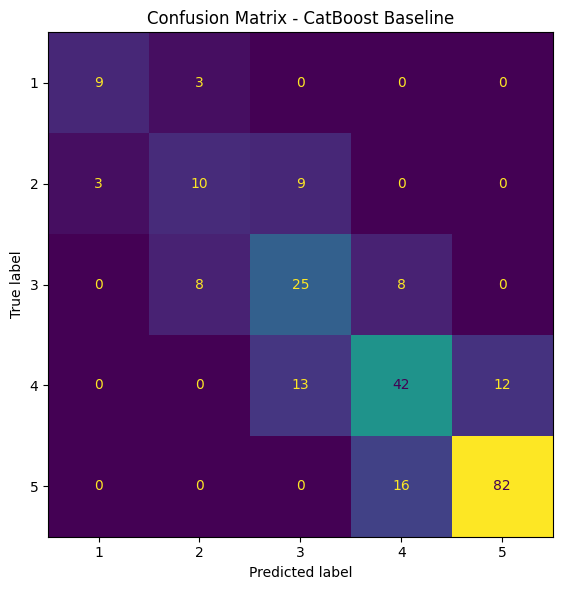

In [11]:
cm = confusion_matrix(y_test, y_pred_test, labels=LABELS)
cm_df = pd.DataFrame(
    cm,
    index=[f"Aktual {label}" for label in LABELS],
    columns=[f"Prediksi {label}" for label in LABELS],
)
display(cm_df)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS,
).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Confusion Matrix - CatBoost Baseline")
plt.tight_layout()
plt.show()

## 11. Feature importance

CatBoost menyediakan feature importance untuk memperlihatkan fitur yang banyak digunakan oleh model dalam meningkatkan prediksi. Nilai ini bersifat prediktif, bukan bukti hubungan sebab-akibat.

,fitur,importance
0,penghasilan_ayah,16.1538
1,penghasilan_ibu,14.8202
2,pengeluaran_bulanan,8.9192
3,sumber_listrik,8.3008
4,jenis_atap,6.5845
5,status_rumah,5.5222
6,pekerjaan_ayah,5.4696
7,pekerjaan_ibu,4.9226
8,sumber_air,4.3462
9,aset_keluarga,4.3247


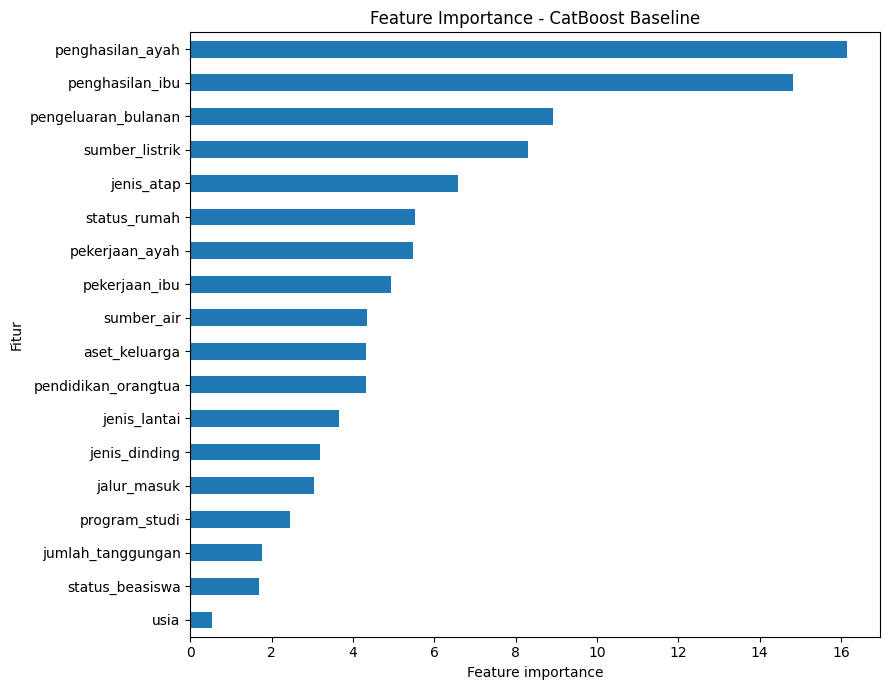

In [12]:
feature_importance_df = pd.DataFrame({
    "fitur": FEATURES,
    "importance": final_model.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.round(4))

plot_data = feature_importance_df.sort_values("importance", ascending=True)
ax = plot_data.plot(
    kind="barh", x="fitur", y="importance", legend=False, figsize=(9, 7)
)
ax.set_title("Feature Importance - CatBoost Baseline")
ax.set_xlabel("Feature importance")
ax.set_ylabel("Fitur")
plt.tight_layout()
plt.show()

## 12. Simpan model dan hasil

Folder `artifacts/` berisi model dan file hasil yang dihasilkan setelah notebook dijalankan. Direktori ini dimasukkan ke `.gitignore` agar file model dan output lokal tidak memenuhi repositori GitHub; hasil dapat dibuat ulang dengan menjalankan notebook.

In [13]:
# Simpan model CatBoost dalam format native CatBoost.
model_path = OUTPUT_DIR / "catboost_baseline_class_weighting.cbm"
final_model.save_model(str(model_path))

# Ekspor tabel metrik dan prediksi agar mudah dipakai kembali.
cv_results.to_csv(OUTPUT_DIR / "cross_validation_per_fold.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cross_validation_summary.csv", index=False)
test_metrics_df.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
report_df.to_csv(OUTPUT_DIR / "classification_report_test.csv", index=True)
per_class_metrics.to_csv(OUTPUT_DIR / "per_class_metrics_test.csv", index=False)
cm_df.to_csv(OUTPUT_DIR / "confusion_matrix_test.csv", index=True)
feature_importance_df.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

prediction_df = pd.DataFrame({
    "target_aktual": y_test.to_numpy(),
    "prediksi": y_pred_test,
})
prediction_df["benar"] = prediction_df["target_aktual"] == prediction_df["prediksi"]
prediction_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

metadata = {
    "project": "CatBoost baseline for student tuition-fee category classification",
    "dataset_note": "Synthetic practice dataset; not the official GEMASTIK dataset and not real student records.",
    "model": "CatBoostClassifier",
    "strategy": "Class Weighting (auto_class_weights='Balanced')",
    "target_column": TARGET_COL,
    "id_column_excluded": ID_COL,
    "features": FEATURES,
    "categorical_features": CAT_COLS,
    "numeric_features": NUM_COLS,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "cv_folds": N_SPLITS,
    "hyperparameter_tuning": False,
    "baseline_parameters": BASELINE_PARAMS,
    "cv_macro_f1_mean": float(cv_results["macro_f1"].mean()),
    "cv_macro_f1_std": float(cv_results["macro_f1"].std(ddof=1)),
    "cv_elapsed_seconds": float(cv_elapsed_seconds),
    "final_fit_seconds": float(final_fit_seconds),
    "test_metrics": {key: float(test_metrics[key]) for key in main_metric_names},
    "reproducibility_note": "The synthetic dataset has been explored during development; test metrics are a development benchmark and not an external validation estimate.",
}
with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Model tersimpan:", model_path)
print("File hasil yang tersimpan:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Model tersimpan: D:\Documents\Gemastik\Tabular\Latihan Kategoti mahahsiswa\gemastik-catboost-baseline-portfolio\artifacts\catboost_baseline_class_weighting.cbm
File hasil yang tersimpan:
- .gitkeep
- catboost_baseline_class_weighting.cbm
- classification_report_test.csv
- confusion_matrix_test.csv
- cross_validation_per_fold.csv
- cross_validation_summary.csv
- feature_importance.csv
- metadata.json
- per_class_metrics_test.csv
- test_metrics.csv
- test_predictions.csv


## 13. Contoh memuat model untuk prediksi

Bagian ini mendemonstrasikan bahwa model yang disimpan dapat dimuat kembali dan digunakan dengan struktur fitur yang sama. Pada aplikasi nyata, data input harus melalui proses penyiapan tipe yang konsisten.

In [14]:
loaded_model = CatBoostClassifier()
loaded_model.load_model(str(model_path))

sample_input = X_test.iloc[[0]].copy()
sample_prediction = np.asarray(loaded_model.predict(sample_input)).ravel()[0]
actual_label = int(y_test.iloc[0])

print("Prediksi kategori:", int(sample_prediction))
print("Kategori aktual  :", actual_label)
print("Prediksi benar?  :", bool(int(sample_prediction) == actual_label))

Prediksi kategori: 5
Kategori aktual  : 5
Prediksi benar?  : True


## 14. Kesimpulan dan batasan

Selesaikan interpretasi setelah notebook dijalankan:

- Gunakan Macro F1 dan Balanced Accuracy sebagai metrik ringkas yang membantu membaca performa antarkelas.
- Periksa recall dan F1 untuk setiap kategori, terutama kelas 1, 2, dan 3.
- Gunakan confusion matrix untuk melihat pola salah klasifikasi.
- Gunakan feature importance sebagai petunjuk eksploratif, bukan kesimpulan kausal.

**Batasan penting:** dataset pada repo ini adalah sintetis. Selain itu, model dan fitur telah dieksplorasi sebelumnya selama pengembangan proyek. Oleh karena itu, hasil test adalah tolok ukur pengembangan, bukan estimasi independen kinerja pada populasi mahasiswa nyata. Untuk klaim generalisasi yang lebih kuat, evaluasi perlu dilakukan pada data eksternal yang belum pernah digunakan dalam pemilihan model.